# Quem são os pacientes com F63 nos CAPS?

O `saude_mental.ipynb` mostrou que o jogo patológico (F63) nos CAPS mais que dobrou a partir de 2024, enquanto o resto
da saúde mental cresceu pouco. Ficaram duas explicações possíveis:
- **(a) reconhecimento e registro:** mais profissionais passaram a registrar F63 em pacientes que já estavam no CAPS;
- **(b) demanda real:** mais gente com problema de jogo chegou ao CAPS.

Aqui seguimos os **pacientes**, e não os procedimentos, para separar as duas:
1. **Subcódigos:** a alta é no jogo patológico (F63.0) ou em outros transtornos de impulso?
2. **Novos ou reclassificados:** quem recebe F63 pela primeira vez já estava no CAPS com outro diagnóstico?
3. **Perfil:** a alta se concentra em **homens jovens**, o perfil do apostador?
4. **Comorbidade:** com quais outros diagnósticos o F63 aparece?

**Dados:** `uv run python -m src.saude_mental.sia_f63_pacientes` (SIA-PS, todas as UFs, 2018 em diante, direto do FTP
do DATASUS). O CNS do paciente vem **criptografado** pelo DATASUS e é estável entre meses, o que permite seguir a
mesma pessoa. **Privacidade (LGPD: dado de saúde é sensível).** As tabelas de nível de paciente ficam só em `data/` (fora do git).
Depois da extração, `src/saude_mental/minimizar_f63.py`:
- troca o CNS por um **pseudônimo novo** (HMAC com uma chave aleatória que só existe em `data/.chave_pseudonimo`), que
  segue a pessoa entre meses mas não bate com nenhuma outra base do SUS;
- reduz **município → UF**, **idade → faixa etária** e **data de início → mês/ano**;
- descarta as colunas que não usamos (estabelecimento, raça/cor, situação de rua, tipo de droga);
- apaga os arquivos intermediários por paciente.

Neste notebook só aparecem **agregados nacionais**, e toda célula com **menos de 5 pacientes é suprimida** (aparece
como vazia), a regra usual para evitar reidentificação em diagnósticos raros. Antes de usar a parte de **seguimento de
pacientes** (seção 2) num trabalho publicado, consultar o CEP: a Resolução CNS 510/2016 dispensa de registro bancos
públicos e agregados, mas a ligação individual, mesmo pseudonimizada, é zona cinza.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import warnings

import matplotlib.pyplot as plt
import pandas as pd
import polars as pl

from src.config import CHOQUES, COPAS, PANDEMIA, PROCESSED

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:.3f}".format)


MIN_CELULA = 5  # células com menos pacientes que isso são suprimidas nas tabelas


def suprimir(df: pl.DataFrame, cols: list[str]) -> pl.DataFrame:
    # contagens < MIN_CELULA viram nulo na tabela exibida (usar ANTES de calcular percentuais a partir delas)
    return df.with_columns([pl.when(pl.col(c) < MIN_CELULA).then(None).otherwise(pl.col(c)).alias(c) for c in cols])


def marcar(ax, desde="2018-01-01"):
    ini, fim = pl.Series(PANDEMIA).str.to_date()
    ax.axvspan(ini, fim, color="gray", alpha=0.15, lw=0)
    for rot, (a, b) in COPAS.items():
        a, b = pl.Series([a, b]).str.to_date()
        ax.axvspan(a, b, color="goldenrod", alpha=0.25, lw=0)
    for d, rot in CHOQUES.items():
        if d >= desde:
            x = pl.Series([d]).str.to_date()[0]
            ax.axvline(x, color="crimson", ls="--", lw=0.8, alpha=0.7)
            ax.text(x, 1.0, " " + rot, rotation=90, va="top", ha="right", fontsize=7, color="crimson", transform=ax.get_xaxis_transform())

## Decisões

**Unidade: paciente distinto por mês.** Uma RAAS tem várias linhas por paciente no mês (uma por procedimento). Em SP,
por exemplo, são ~430 mil linhas para ~107 mil pacientes num mês. As contagens `raas_*` do `saude_mental.ipynb` são de
**procedimentos**. Aqui contamos **pacientes** (CNS distintos).

**F63 principal ou associado.** O F63 pode ser o CID principal da RAAS ou o CID associado (comorbidade). Guardamos os dois
e mostramos separado, porque um aumento do F63 só como **associado** em quem já tem outro diagnóstico principal é sinal
de registro mais completo, ou seja, da explicação (a).

**Subcódigos.** O F63 junta transtornos diferentes:
- **"Jogo provável":** F63.0 (jogo patológico), F63 sem subcódigo (o SUS muitas vezes registra só 3 caracteres),
  F63.8 (outros) e F63.9 (não especificado);
- **"Não jogo":** F63.1 (piromania), F63.2 (cleptomania), F63.3 (tricotilomania), que não têm relação com apostas e servem
  de **placebo**: se subirem junto, a alta é de registro do capítulo inteiro, não de jogo.

**Decisão tomada depois de ver os dados — medida principal = F63.0 explícito.** O plano inicial era usar "jogo
provável". Ao rodar, vimos que **36–38% dos pacientes-mês com F63.8 e F63.9 têm menos de 18 anos**, contra **4–7% no
F63.0**. Em crianças e adolescentes (CAPSi), esses códigos registram outros transtornos de impulso, não jogo. Por isso a
medida principal passa a ser o **F63.0 explícito**, que é a mais específica. "Jogo provável" fica como medida ampla. Como
é uma escolha *post hoc*, mostramos as duas em todas as tabelas: o leitor vê que a conclusão não depende dela.

**Período.** Jan/2018 em diante, descartando os 2 últimos meses (envio incompleto), como no `saude_mental.ipynb`.

**Ligação entre UFs.** Assumimos que a criptografia do CNS é a mesma em todos os arquivos. Verificamos abaixo se há
pacientes que aparecem em mais de uma UF, o que só acontece se a chave for comum.

In [2]:
reg = (pl.read_parquet(PROCESSED / "sia_f63_registros.parquet")
       .with_columns(pl.col("cmp").str.to_date("%Y%m").alias("data"),
                     pl.col("CIDPRI").str.starts_with("F63").alias("f63_pri"))
       .with_columns(pl.when(pl.col("f63_pri")).then(pl.col("CIDPRI")).otherwise(pl.col("CIDASSOC")).alias("cid_f63"))
       .with_columns(pl.col("cid_f63").is_in(["F63", "F630", "F638", "F639"]).alias("jogo_provavel"),
                     (pl.col("cid_f63") == "F630").alias("f630")))
meses = sorted(reg["data"].unique())
corte = meses[-3]
reg = reg.filter(pl.col("data").is_between(pl.date(2018, 1, 1), corte))
print(f"{reg['id'].n_unique():,} pacientes distintos com F63 (principal ou associado), {reg['data'].min()} a {reg['data'].max()}")
multi_uf = reg.group_by("id").agg(pl.col("cod_uf").n_unique()).filter(pl.col("cod_uf") > 1).height
print(f"pacientes que aparecem em mais de uma UF: {multi_uf:,}  (> 0 indica que a chave é comum entre UFs)")
suprimir(reg.group_by("cid_f63").agg(pl.col("id").n_unique().alias("pacientes")), ["pacientes"]).sort("pacientes", descending=True, nulls_last=True).to_pandas().set_index("cid_f63")

9,189 pacientes distintos com F63 (principal ou associado), 2018-01-01 a 2026-06-01
pacientes que aparecem em mais de uma UF: 9  (> 0 indica que a chave é comum entre UFs)


,pacientes
cid_f63,
F63,3082
F638,2166
F630,2064
F633,1197
F639,823
F632,344
F631,125


## 1. Subcódigos: a alta é de jogo?

Primeiro, a idade em cada subcódigo, que motivou a escolha do F63.0 como medida principal:

In [3]:
pm_sub = reg.unique(["id", "data", "cid_f63"])
suprimir(pm_sub.group_by("cid_f63").agg(pl.len().alias("pacientes_mes"),
                                         ((pl.col("faixa") == "0-17").mean() * 100).alias("% menores de 18"),
                                         ((pl.col("SEXOPAC") == "M").mean() * 100).alias("% homens")), ["pacientes_mes"]
         ).sort("pacientes_mes", descending=True).to_pandas().set_index("cid_f63")

,pacientes_mes,% menores de 18,% homens
cid_f63,,,
F63,8432,24.360,47.853
F638,7541,37.594,55.457
F633,5082,52.184,21.547
F630,4893,6.581,55.896
F639,3048,35.728,53.839
F632,1394,21.019,26.686
F631,238,37.395,40.336


In [4]:
por_sub = (reg.filter(pl.col("f63_pri")).with_columns(pl.col("data").dt.year().alias("ano"))
           .group_by("ano", "cid_f63").agg(pl.col("id").n_unique().alias("p"))
           .pivot(on="cid_f63", index="ano", values="p").fill_null(0).sort("ano"))
por_sub = por_sub.select("ano", *sorted(c for c in por_sub.columns if c != "ano"))
suprimir(por_sub, [c for c in por_sub.columns if c != "ano"]).to_pandas().set_index("ano")

,F63,F630,F631,F632,F633,F638,F639
ano,,,,,,,
2018,184,36,10,44,184,127,80
2019,205,52,10,54,155,179,110
2020,233,54,6,45,162,166,79
2021,272,63,13,45,179,212,106
2022,315,105,8,43,183,274,122
2023,379,140,14,37,182,334,99
2024,457,261,16,50,188,423,112
2025,690,769,20,60,187,519,168
2026,501,742,11,44,113,345,109


Pacientes distintos por ano com cada subcódigo como CID **principal**.

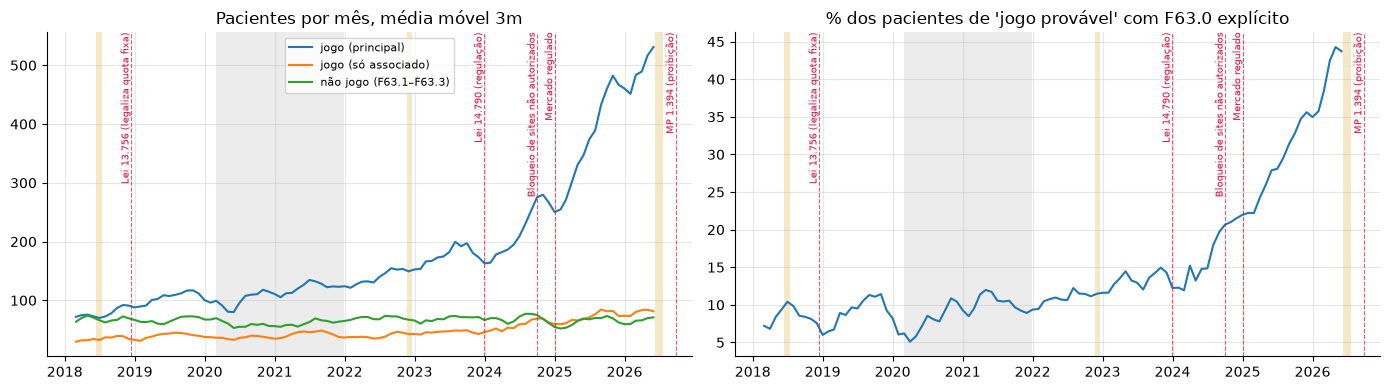

In [5]:
mensal = (reg.group_by("data").agg(
            pl.col("id").filter(pl.col("f63_pri") & pl.col("jogo_provavel")).n_unique().alias("jogo (principal)"),
            pl.col("id").filter(~pl.col("f63_pri") & pl.col("jogo_provavel")).n_unique().alias("jogo (só associado)"),
            pl.col("id").filter(~pl.col("jogo_provavel")).n_unique().alias("não jogo (F63.1–F63.3)"),
            pl.col("id").filter(pl.col("cid_f63") == "F630").n_unique().alias("F63.0 explícito"))
          .sort("data"))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for c in ["jogo (principal)", "jogo (só associado)", "não jogo (F63.1–F63.3)"]:
    axes[0].plot(mensal["data"], mensal[c].rolling_mean(3), label=c)
axes[0].legend(fontsize=8); axes[0].set_title("Pacientes por mês, média móvel 3m")
share = mensal.with_columns((pl.col("F63.0 explícito") / (pl.col("jogo (principal)") + pl.col("jogo (só associado)")) * 100).alias("pct"))
axes[1].plot(share["data"], share["pct"].rolling_mean(3)); axes[1].set_title("% dos pacientes de 'jogo provável' com F63.0 explícito")
for ax in axes: marcar(ax)
plt.tight_layout()

In [6]:
anual = (reg.with_columns(pl.col("data").dt.year().alias("ano")).group_by("ano").agg(
            pl.col("id").filter(pl.col("jogo_provavel") & pl.col("f63_pri")).n_unique().alias("jogo_principal"),
            pl.col("id").filter(pl.col("jogo_provavel") & ~pl.col("f63_pri")).n_unique().alias("jogo_so_associado"),
            pl.col("id").filter(~pl.col("jogo_provavel")).n_unique().alias("nao_jogo"),
            pl.col("id").filter(pl.col("f630")).n_unique().alias("F63.0_explicito"),
            pl.col("data").n_unique().alias("meses"))
         .sort("ano"))
suprimir(anual, ["jogo_principal", "jogo_so_associado", "nao_jogo", "F63.0_explicito"]).to_pandas().set_index("ano")

,jogo_principal,jogo_so_associado,nao_jogo,F63.0_explicito,meses
ano,,,,,
2018,423,159,296,46,12
2019,531,193,283,67,12
2020,524,160,269,63,12
2021,634,219,314,81,12
2022,790,227,338,124,12
2023,923,227,311,158,12
2024,1219,338,328,299,12
2025,2049,415,338,856,12
2026,1647,295,216,849,6


Contagem anual de **pacientes distintos no ano** (cada pessoa conta uma vez por ano). O último ano é parcial (ver `meses`).

## 2. Pacientes novos ou reclassificados?

Para cada paciente, `t0` é o **primeiro mês com F63** (principal ou associado). Olhamos o histórico dele no CAPS nos
**12 meses anteriores** a `t0`, com qualquer CID:
- **novo:** nenhum registro no CAPS nos 12 meses anteriores. Chegou ao CAPS já com F63;
- **já estava no CAPS:** tinha registro com outro CID nos 12 meses anteriores. O F63 foi **acrescentado ou trocado**.

**Decisão — janela fixa de 12 meses:** se usássemos "qualquer registro desde 2018", os anos mais recentes teriam mais
histórico para olhar e pareceriam ter mais pacientes "já no CAPS" só por isso. Com janela fixa, todos os anos são
comparáveis. Por isso a classificação começa em **2019** (o primeiro ano com 12 meses de histórico).

**Ressalva:** "novo no CAPS" não quer dizer caso novo de vício. A pessoa pode ter sido tratada antes na rede privada,
na atenção básica ou fora do período.

In [7]:
hist = (pl.read_parquet(PROCESSED / "sia_f63_historico.parquet")
        .with_columns(pl.col("cmp").str.to_date("%Y%m").alias("data")))
t0 = reg.group_by("id").agg(pl.col("data").min().alias("t0"), pl.col("jogo_provavel").any().alias("jogo"))
anterior = (hist.join(t0, on="id")
            .filter((pl.col("data") < pl.col("t0")) & (pl.col("data") >= pl.col("t0").dt.offset_by("-12mo"))))
grupo_cid = (pl.when(pl.col("CIDPRI").str.starts_with("F1")).then(pl.lit("F10–F19 substâncias"))
             .when(pl.col("CIDPRI").str.starts_with("F2")).then(pl.lit("F20–F29 psicoses"))
             .when(pl.col("CIDPRI").str.starts_with("F3")).then(pl.lit("F30–F39 humor"))
             .when(pl.col("CIDPRI").str.starts_with("F4")).then(pl.lit("F40–F48 ansiedade"))
             .when(pl.col("CIDPRI").str.starts_with("F6")).then(pl.lit("F60–F69 personalidade/impulsos"))
             .when(pl.col("CIDPRI").str.starts_with("F")).then(pl.lit("outros F"))
             .otherwise(pl.lit("não F / vazio")))
prev = (anterior.with_columns(grupo_cid.alias("grupo_prev"))
        .group_by("id").agg(pl.col("grupo_prev").mode().first()))
def classificar(definicao):
    t = reg.filter(pl.col(definicao)).group_by("id").agg(pl.col("data").min().alias("t0"))
    ant = hist.join(t, on="id").filter((pl.col("data") < pl.col("t0")) & (pl.col("data") >= pl.col("t0").dt.offset_by("-12mo")))
    tem = ant.select("id").unique().with_columns(pl.lit(True).alias("tinha"))
    c = (t.filter(pl.col("t0") >= pl.date(2019, 1, 1)).join(tem, on="id", how="left")
         .with_columns(pl.col("t0").dt.year().alias("ano_t0"), pl.col("tinha").fill_null(False)))
    return (c.group_by("ano_t0").agg((~pl.col("tinha")).sum().alias("novo"), pl.col("tinha").sum().alias("já estava no CAPS"))
            .with_columns((pl.col("novo") / (pl.col("novo") + pl.col("já estava no CAPS")) * 100).alias("% novos")).sort("ano_t0"))

print("F63.0 explícito (medida principal):")
display(suprimir(classificar("f630"), ["novo", "já estava no CAPS"]).to_pandas().set_index("ano_t0"))
print("Jogo provável (medida ampla):")

cls = (t0.filter(pl.col("jogo") & (pl.col("t0") >= pl.date(2019, 1, 1)))
       .join(prev, on="id", how="left")
       .with_columns(pl.col("t0").dt.year().alias("ano_t0"),
                     pl.when(pl.col("grupo_prev").is_null()).then(pl.lit("novo")).otherwise(pl.lit("já estava no CAPS")).alias("tipo")))
tab_cls = (cls.group_by("ano_t0", "tipo").len().pivot(on="tipo", index="ano_t0", values="len").fill_null(0)
           .with_columns((pl.col("novo") / (pl.col("novo") + pl.col("já estava no CAPS")) * 100).alias("% novos")).sort("ano_t0"))
suprimir(tab_cls, ["novo", "já estava no CAPS"]).to_pandas().set_index("ano_t0")

F63.0 explícito (medida principal):


,novo,já estava no CAPS,% novos
ano_t0,,,
2019,35,19,64.815
2020,20,20,50.000
2021,38,24,61.290
2022,63,36,63.636
2023,80,41,66.116
2024,178,74,70.635
2025,526,229,69.669
2026,495,140,77.953


Jogo provável (medida ampla):


,novo,já estava no CAPS,% novos
ano_t0,,,
2019,312,191,62.028
2020,265,190,58.242
2021,345,240,58.974
2022,398,304,56.695
2023,417,317,56.812
2024,650,441,59.578
2025,1118,733,60.400
2026,844,350,70.687


In [8]:
prev_tab = (cls.filter(pl.col("tipo") == "já estava no CAPS")
            .with_columns(pl.when(pl.col("ano_t0") <= 2023).then(pl.lit("2019–2023")).otherwise(pl.lit("2024+")).alias("periodo"))
            .group_by("periodo", "grupo_prev").len()
            .with_columns((pl.col("len") / pl.col("len").sum().over("periodo") * 100).alias("%"))
            .with_columns(pl.when(pl.col("len") < MIN_CELULA).then(None).otherwise(pl.col("%")).alias("%"))
            .pivot(on="periodo", index="grupo_prev", values="%").sort("2024+", descending=True))
prev_tab.to_pandas().set_index("grupo_prev")

,2024+,2019–2023
grupo_prev,,
outros F,33.924,31.884
F30–F39 humor,18.307,24.316
F40–F48 ansiedade,18.045,15.298
F10–F19 substâncias,13.714,7.407
F60–F69 personalidade/impulsos,6.496,9.259
F20–F29 psicoses,5.446,7.327
não F / vazio,4.068,4.509


Diagnóstico principal mais frequente nos 12 meses anteriores ao primeiro F63, entre os que **já estavam no CAPS**
(% de cada período).

## 3. Perfil: a alta se concentra em homens jovens?

Comparamos a composição por sexo e idade dos pacientes de **jogo provável** com a de **todos os pacientes de saúde
mental** (CID principal F).

**Decisão — paciente-mês:** a base de saúde mental vem agregada por arquivo (UF × mês), então só dá para contar
**pacientes-mês** (cada pessoa conta uma vez em cada mês em que foi atendida). Para comparar igual com igual, o F63
também é contado em pacientes-mês nesta seção.

In [9]:
perfil = pl.read_parquet(PROCESSED / "sia_perfil.parquet").with_columns(pl.col("cmp").str.to_date("%Y%m").alias("data"))
perfil = perfil.filter(pl.col("data").is_between(pl.date(2018, 1, 1), corte) & pl.col("faixa").is_not_null())
def pm(flag, rot):
    return (reg.filter(pl.col(flag) & pl.col("faixa").is_not_null())
            .unique(["id", "data"]).group_by("data", "SEXOPAC", "faixa").len("pacientes")
            .with_columns(pl.lit(rot).alias("grupo")).select("data", "grupo", "SEXOPAC", "faixa", "pacientes"))
base = pl.concat([pm("f630", "F63.0"), pm("jogo_provavel", "jogo provável"),
                  perfil.filter(pl.col("grupo") == "mental").with_columns(pl.lit("saúde mental").alias("grupo"))
                  .select("data", "grupo", "SEXOPAC", "faixa", pl.col("pacientes").cast(pl.UInt32))])
base = base.with_columns(pl.col("data").dt.year().alias("ano"))

def composicao(anos):
    d = base.filter(pl.col("ano").is_in(anos)).group_by("grupo", "SEXOPAC", "faixa").agg(pl.col("pacientes").sum())
    d = d.with_columns((pl.col("pacientes") / pl.col("pacientes").sum().over("grupo") * 100).alias("%"))
    return d.with_columns(pl.when(pl.col("pacientes") < MIN_CELULA).then(None).otherwise(pl.col("%")).alias("%"))

comp = composicao([2025]).with_columns((pl.col("SEXOPAC") + " " + pl.col("faixa")).alias("celula"))
tab = comp.pivot(on="grupo", index="celula", values="%").sort("celula")
tab.to_pandas().set_index("celula")

,jogo provável,saúde mental,F63.0
celula,,,
F 0-17,10.468,9.012,1.040
F 18-24,5.474,5.005,6.732
F 25-34,13.335,8.940,19.706
F 35-44,8.896,11.052,10.955
F 45-59,6.399,12.481,6.487
F 60+,2.164,3.874,2.264
M 0-17,14.352,13.083,3.060
M 18-24,8.027,5.906,8.507
M 25-34,13.020,9.039,18.911


F63.0  saúde mental  jogo provável
SEXOPAC faixa                                    
F       0-17   1.545         1.336          1.945
        18-24 12.222         1.240          2.014
        25-34 23.000         1.288          3.466
        35-44 19.889         1.294          2.454
        45-59  5.300         1.306          3.009
        60+    2.643         1.292          2.854
M       0-17   2.083         1.521          2.296
        18-24  5.346         1.164          2.494
        25-34  8.132         1.240          3.538
        35-44  7.893         1.253          2.886
        45-59  3.828         1.276          1.680
        60+    1.941         1.322          1.483

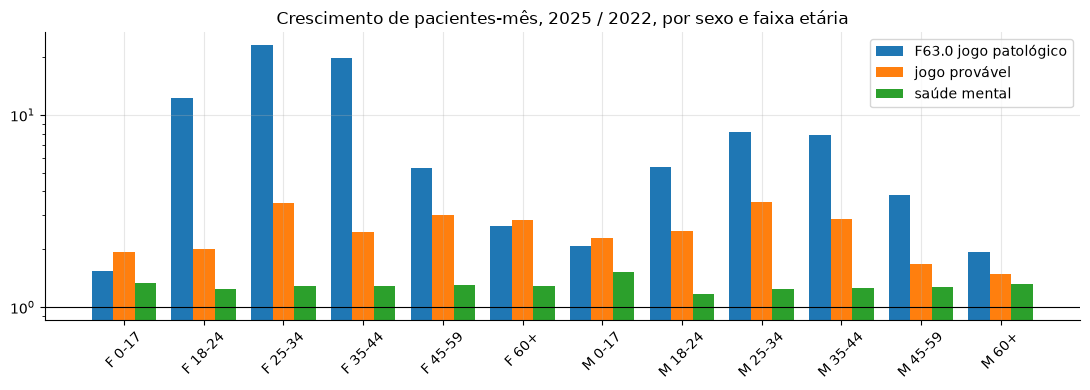

In [10]:
cresc = (base.filter(pl.col("ano").is_in([2022, 2025])).group_by("grupo", "SEXOPAC", "faixa", "ano").agg(pl.col("pacientes").sum())
         .pivot(on="ano", index=["grupo", "SEXOPAC", "faixa"], values="pacientes")
         .with_columns(pl.when((pl.col("2025") < MIN_CELULA) | (pl.col("2022") < MIN_CELULA)).then(None)
                       .otherwise(pl.col("2025") / pl.col("2022")).alias("razão 2025/2022"))
         .pivot(on="grupo", index=["SEXOPAC", "faixa"], values="razão 2025/2022").sort("SEXOPAC", "faixa"))
fig, ax = plt.subplots(figsize=(11, 4))
x = range(cresc.height)
ax.bar([i - 0.27 for i in x], cresc["F63.0"], width=0.27, label="F63.0 jogo patológico")
ax.bar([i for i in x], cresc["jogo provável"], width=0.27, label="jogo provável")
ax.bar([i + 0.27 for i in x], cresc["saúde mental"], width=0.27, label="saúde mental")
ax.set_yscale("log")
ax.set_xticks(list(x), [f"{s} {f}" for s, f in zip(cresc["SEXOPAC"], cresc["faixa"])], rotation=45)
ax.axhline(1, color="k", lw=0.8); ax.legend(); ax.set_title("Crescimento de pacientes-mês, 2025 / 2022, por sexo e faixa etária")
plt.tight_layout()
cresc.to_pandas().set_index(["SEXOPAC", "faixa"])

## 4. Comorbidade: com o que o F63 aparece?

Entre os pacientes-mês de jogo provável com F63 como **principal**, qual é o CID **associado**? E quando o F63 é
**associado**, qual é o principal?

In [11]:
def grupo(col):
    return (pl.when(pl.col(col).fill_null("") == "").then(pl.lit("nenhum"))
            .when(pl.col(col).str.starts_with("F1")).then(pl.lit("F10–F19 substâncias"))
            .when(pl.col(col).str.starts_with("F2")).then(pl.lit("F20–F29 psicoses"))
            .when(pl.col(col).str.starts_with("F3")).then(pl.lit("F30–F39 humor"))
            .when(pl.col(col).str.starts_with("F4")).then(pl.lit("F40–F48 ansiedade"))
            .when(pl.col(col).str.starts_with("F6")).then(pl.lit("F60–F69 personalidade/impulsos"))
            .when(pl.col(col).str.starts_with("F")).then(pl.lit("outros F"))
            .otherwise(pl.lit("não F")))

j = reg.filter(pl.col("jogo_provavel") & (pl.col("data") >= pl.date(2024, 1, 1))).unique(["id", "data"])
a = j.filter(pl.col("f63_pri")).group_by(grupo("CIDASSOC").alias("cid")).len("F63 principal → associado")
b = j.filter(~pl.col("f63_pri")).group_by(grupo("CIDPRI").alias("cid")).len("F63 associado → principal")
com = a.join(b, on="cid", how="full", coalesce=True).fill_null(0)
cols_com = [c for c in com.columns if c != "cid"]
com = com.with_columns([pl.when(pl.col(c) < MIN_CELULA).then(None).otherwise(pl.col(c) / pl.col(c).sum() * 100).alias(c) for c in cols_com])
com.sort("F63 principal → associado", descending=True).to_pandas().set_index("cid")

,F63 principal → associado,F63 associado → principal
cid,,
nenhum,78.814,NaN
F60–F69 personalidade/impulsos,9.561,7.266
F40–F48 ansiedade,3.456,25.037
F30–F39 humor,3.096,22.926
outros F,2.327,18.508
F10–F19 substâncias,1.421,19.588
não F,0.857,2.307
F20–F29 psicoses,0.467,4.369


Percentuais de pacientes-mês de 2024 em diante (período da alta). Células vazias: menos de 5 pacientes-mês (suprimidas).

## Leitura

**1. A alta é de jogo patológico, e é grande.** Pacientes com **F63.0** (principal ou associado): 46–81/ano em 2018–21,
124 em 2022, 299 em 2024, **856 em 2025**, e **849 só no 1º semestre de 2026**. É ~7× de 2022 para 2025. Os
transtornos de impulso **sem relação com jogo** (piromania, cleptomania, tricotilomania; o placebo) ficaram parados em
~300–340 pacientes/ano. Então não é uma mudança geral no registro do capítulo F63.

Parte da alta do F63.0 pode ser **registro mais preciso** (o profissional passa a escrever F63.0 em vez de só F63).
Mas o F63 sem subcódigo também cresceu (315 → 690 entre 2022 e 2025), então a soma cresce, não só a troca de código.

**2. Não é reclassificação de quem já estava no CAPS.** Se a alta viesse de profissionais acrescentando F63 a pacientes
antigos, a fração de **novos** cairia. Ela **subiu**: entre os pacientes com F63.0, os que não tinham nenhum registro
no CAPS nos 12 meses anteriores eram 50–66% em 2019–23, 70% em 2024–25 e 78% em 2026. Em números absolutos, os novos
passaram de 63 (2022) para 526 (2025). A medida ampla (jogo provável) dá o mesmo padrão, mais suave (57% → 60% → 71%).

Isso **enfraquece a explicação (a) na versão "recodificação"**. Ainda fica uma versão mais fraca: mais **reconhecimento
social** do problema (CPI, imprensa, campanhas) leva mais gente a **procurar** ajuda, sem que haja mais casos. Os dados
do CAPS não separam "mais casos" de "mais procura". Mas, em qualquer um dos dois, a **demanda que chega ao SUS
é real e nova**.

**3. O perfil não é o esperado: são adultos jovens, e quase metade mulheres.**
- Em 2025, **25–34 anos** é ~39% dos pacientes-mês com F63.0, contra ~18% no total da saúde mental. Quase não há
  menores (~4%).
- **Mulheres são ~47%**. O maior crescimento desde 2022 é de **mulheres de 18 a 44 anos** (12× a 23×), contra 5× a 8×
  nos homens da mesma idade. Entre todos os pacientes de saúde mental, o crescimento foi de ~1,2–1,5× em todas as células.
- A hipótese de que o vício viria de **homens jovens apostando em futebol** não descreve bem quem chega ao CAPS.
  Uma explicação plausível são os **cassinos online** ("tigrinho" e similares), que cresceram junto com as bets e têm
  público feminino grande. O DataSenado 2024 já mostrava 38% de mulheres entre os apostadores. Outra explicação,
  não excludente: mulheres procuram tratamento mais que homens em quase todos os transtornos. A comparação com a base
  de saúde mental (que já tem esse viés) atenua, mas não elimina essa diferença.
- ⚠ As bases de 2022 por célula são pequenas (dezenas de pacientes-mês), então as razões por célula são ruidosas.
  O padrão geral (crescimento muito maior em mulheres adultas) é robusto. Os valores exatos, não.

**4. Comorbidade.** Quando o F63 é o diagnóstico principal, em ~79% dos casos não há CID associado. Quando ele aparece
como **associado**, o principal costuma ser ansiedade (25%), humor/depressão (23%) ou substâncias (20%). Entre quem já
estava no CAPS antes do F63, a fração que estava por **substâncias** dobrou (7% → 14%) no período da alta.

**Resumo para o trabalho:** a partir de 2024, o atendimento por **jogo patológico (F63.0)** nos CAPS cresceu ~7×,
puxado por **pacientes novos** na rede e com perfil de **adultos de 18 a 44 anos, quase metade mulheres**, enquanto
transtornos de impulso sem relação com jogo ficaram estáveis. É a evidência mais direta, neste projeto, de um custo das
apostas para o SUS. A limitação central é que ela não diferencia mais casos de mais procura.

**Próximos passos:**
1. **SIH** (internações com F63) e **SIM** (suicídio): mesmo teste, em casos graves.
2. **UF de residência × perfil:** a alta em mulheres é nacional ou concentrada?
3. **Depois da MP 1.394** (dados de out/2026 em diante): se a procura continuar subindo, isso indica estoque de vício já
   formado; se cair, indica procura ligada à exposição corrente.